# 01 — Análise Exploratória de Dados (EDA)
### Tech Challenge — Fase 2 | Pós Tech Data Analytics (14DTAT) | Luis Guilherme Betarelli Lopes (RM374939)

Este notebook cobre a **compreensão do problema** e a **análise exploratória** da base
de dados usada para classificar vinhos como Alta Qualidade (nota ≥ 7) ou
Baixa/Média Qualidade (nota < 7).

**Fonte do dataset:** [Wine Quality Dataset (Kaggle, yasserh)](https://www.kaggle.com/datasets/yasserh/wine-quality-dataset)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42

## 1. Compreensão do problema

A avaliação tradicional de qualidade de um vinho depende de especialistas
realizando análise sensorial (aroma, sabor, acidez, equilíbrio) — um processo
subjetivo e difícil de padronizar em escala.

Este projeto usa variáveis físico-químicas, medidas durante a produção, para
prever a qualidade final do vinho, tratando o problema como uma
**classificação binária**:

- **1 — Alta Qualidade**: `quality >= 7`
- **0 — Baixa/Média Qualidade**: `quality < 7`

O limiar de 7 foi definido no enunciado do desafio e reflete a prática comum na
literatura sobre este dataset (separar os vinhos "premium" do restante).

In [2]:
df = pd.read_csv("../data/raw/WineQT.csv")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [3]:
print("Formato da base (linhas, colunas):", df.shape)
df.info()

Formato da base (linhas, colunas): (1143, 13)
<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1143.0,8.311111,1.747595,4.60000,7.10000,7.90000,9.100000,15.90000
volatile acidity,1143.0,0.531339,0.179633,0.12000,0.39250,0.52000,0.640000,1.58000
citric acid,1143.0,0.268364,0.196686,0.00000,0.09000,0.25000,0.420000,1.00000
residual sugar,1143.0,2.532152,1.355917,0.90000,1.90000,2.20000,2.600000,15.50000
chlorides,1143.0,0.086933,0.047267,0.01200,0.07000,0.07900,0.090000,0.61100
free sulfur dioxide,1143.0,15.615486,10.250486,1.00000,7.00000,13.00000,21.000000,68.00000
total sulfur dioxide,1143.0,45.914698,32.782130,6.00000,21.00000,37.00000,61.000000,289.00000
density,1143.0,0.996730,0.001925,0.99007,0.99557,0.99668,0.997845,1.00369
pH,1143.0,3.311015,0.156664,2.74000,3.20500,3.31000,3.400000,4.01000
sulphates,1143.0,0.657708,0.170399,0.33000,0.55000,0.62000,0.730000,2.00000


**Dicionário de variáveis** (todas físico-químicas, medidas em laboratório):

| Variável | Descrição |
|---|---|
| fixed acidity | Acidez fixa (ácidos não voláteis) |
| volatile acidity | Acidez volátil (associada a defeitos de fermentação) |
| citric acid | Ácido cítrico |
| residual sugar | Açúcar residual após fermentação |
| chlorides | Cloretos (sal) |
| free sulfur dioxide | Dióxido de enxofre livre |
| total sulfur dioxide | Dióxido de enxofre total |
| density | Densidade |
| pH | Nível de acidez/basicidade |
| sulphates | Sulfatos (conservante) |
| alcohol | Teor alcoólico |
| quality | Nota de qualidade (3–8), atribuída por especialistas — variável alvo original |
| Id | Identificador sequencial da amostra — sem valor preditivo |

## 2. Análise Exploratória de Dados

### 2.1 Dados faltantes e duplicados

In [5]:
print("Valores nulos por coluna:")
print(df.isnull().sum())
print("\nLinhas duplicadas:", df.duplicated().sum())

Valores nulos por coluna:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

Linhas duplicadas: 0


Não há valores nulos na base. Há algumas linhas duplicadas (registros
físico-químicos idênticos) — plausível no contexto de amostras de vinho (lotes
parecidos), e não necessariamente um erro de coleta. O tratamento formal de
nulos/duplicados fica documentado no notebook 02 (pré-processamento).

### 2.2 Distribuição da variável alvo

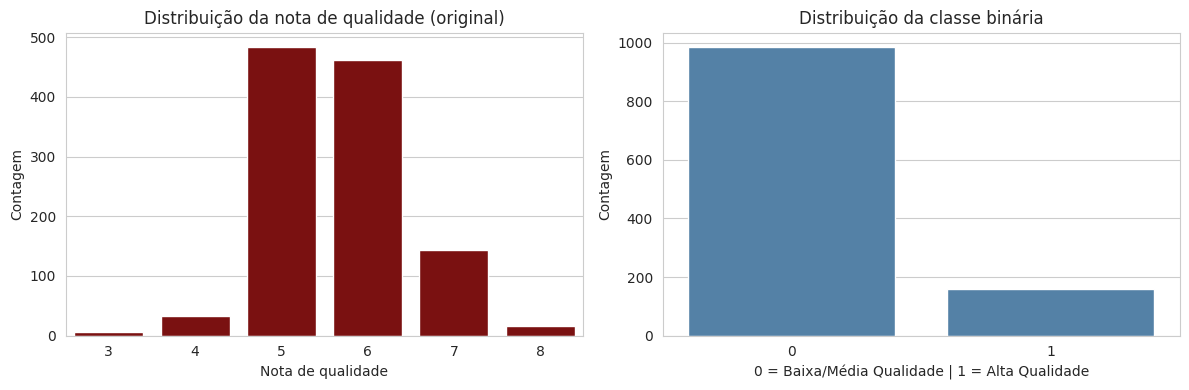

quality
0    0.860892
1    0.139108
Name: proporção, dtype: float64

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x="quality", data=df, ax=axes[0], color="darkred")
axes[0].set_title("Distribuição da nota de qualidade (original)")
axes[0].set_xlabel("Nota de qualidade")
axes[0].set_ylabel("Contagem")

quality_label = (df["quality"] >= 7).astype(int)
sns.countplot(x=quality_label, ax=axes[1], color="steelblue")
axes[1].set_title("Distribuição da classe binária")
axes[1].set_xlabel("0 = Baixa/Média Qualidade | 1 = Alta Qualidade")
axes[1].set_ylabel("Contagem")

plt.tight_layout()
plt.show()

quality_label.value_counts(normalize=True).rename("proporção")

**Interpretação — balanceamento das classes:** a classe "Alta Qualidade"
representa apenas ~14% das amostras, contra ~86% de "Baixa/Média Qualidade".
A base é **desbalanceada**. Isso tem duas implicações práticas para as próximas
etapas:

1. Acurácia sozinha não é uma métrica confiável — um modelo que sempre prevê
   "Baixa/Média Qualidade" já acertaria ~86% das vezes sem aprender nada útil.
2. Vamos usar separação estratificada (notebook 02) e considerar
   `class_weight="balanced"` nos modelos de árvore (notebook 03) para não
   deixar os algoritmos enviesados para a classe majoritária.

### 2.3 Distribuição das variáveis físico-químicas

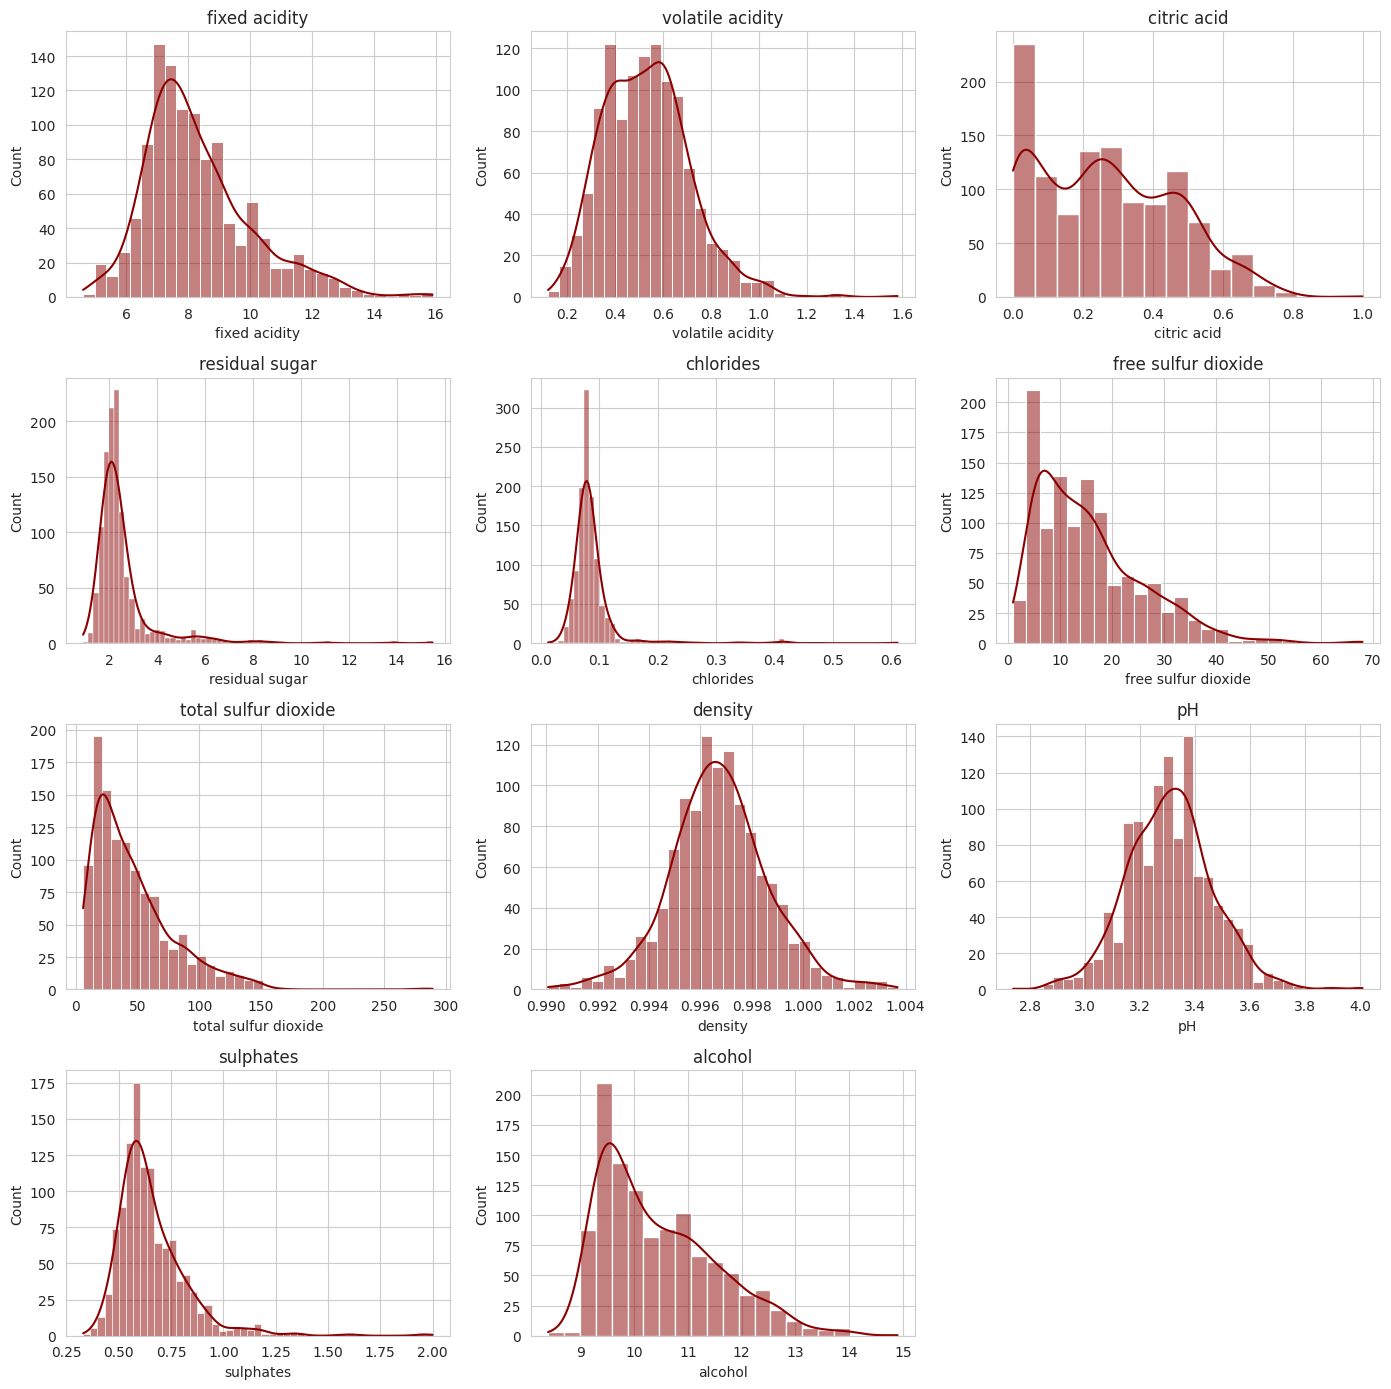

In [7]:
features = [c for c in df.columns if c not in ["quality", "Id"]]

fig, axes = plt.subplots(4, 3, figsize=(14, 14))
axes = axes.flatten()
for i, col in enumerate(features):
    sns.histplot(df[col], kde=True, ax=axes[i], color="darkred")
    axes[i].set_title(col)
axes[-1].axis("off")
plt.tight_layout()
plt.show()

**Interpretação:** a maioria das variáveis apresenta assimetria à direita
(cauda longa de valores altos), com destaque para `residual sugar`,
`chlorides` e `free/total sulfur dioxide`, que concentram a maior parte dos
valores em uma faixa estreita com alguns outliers mais extremos.

### 2.4 Outliers por variável

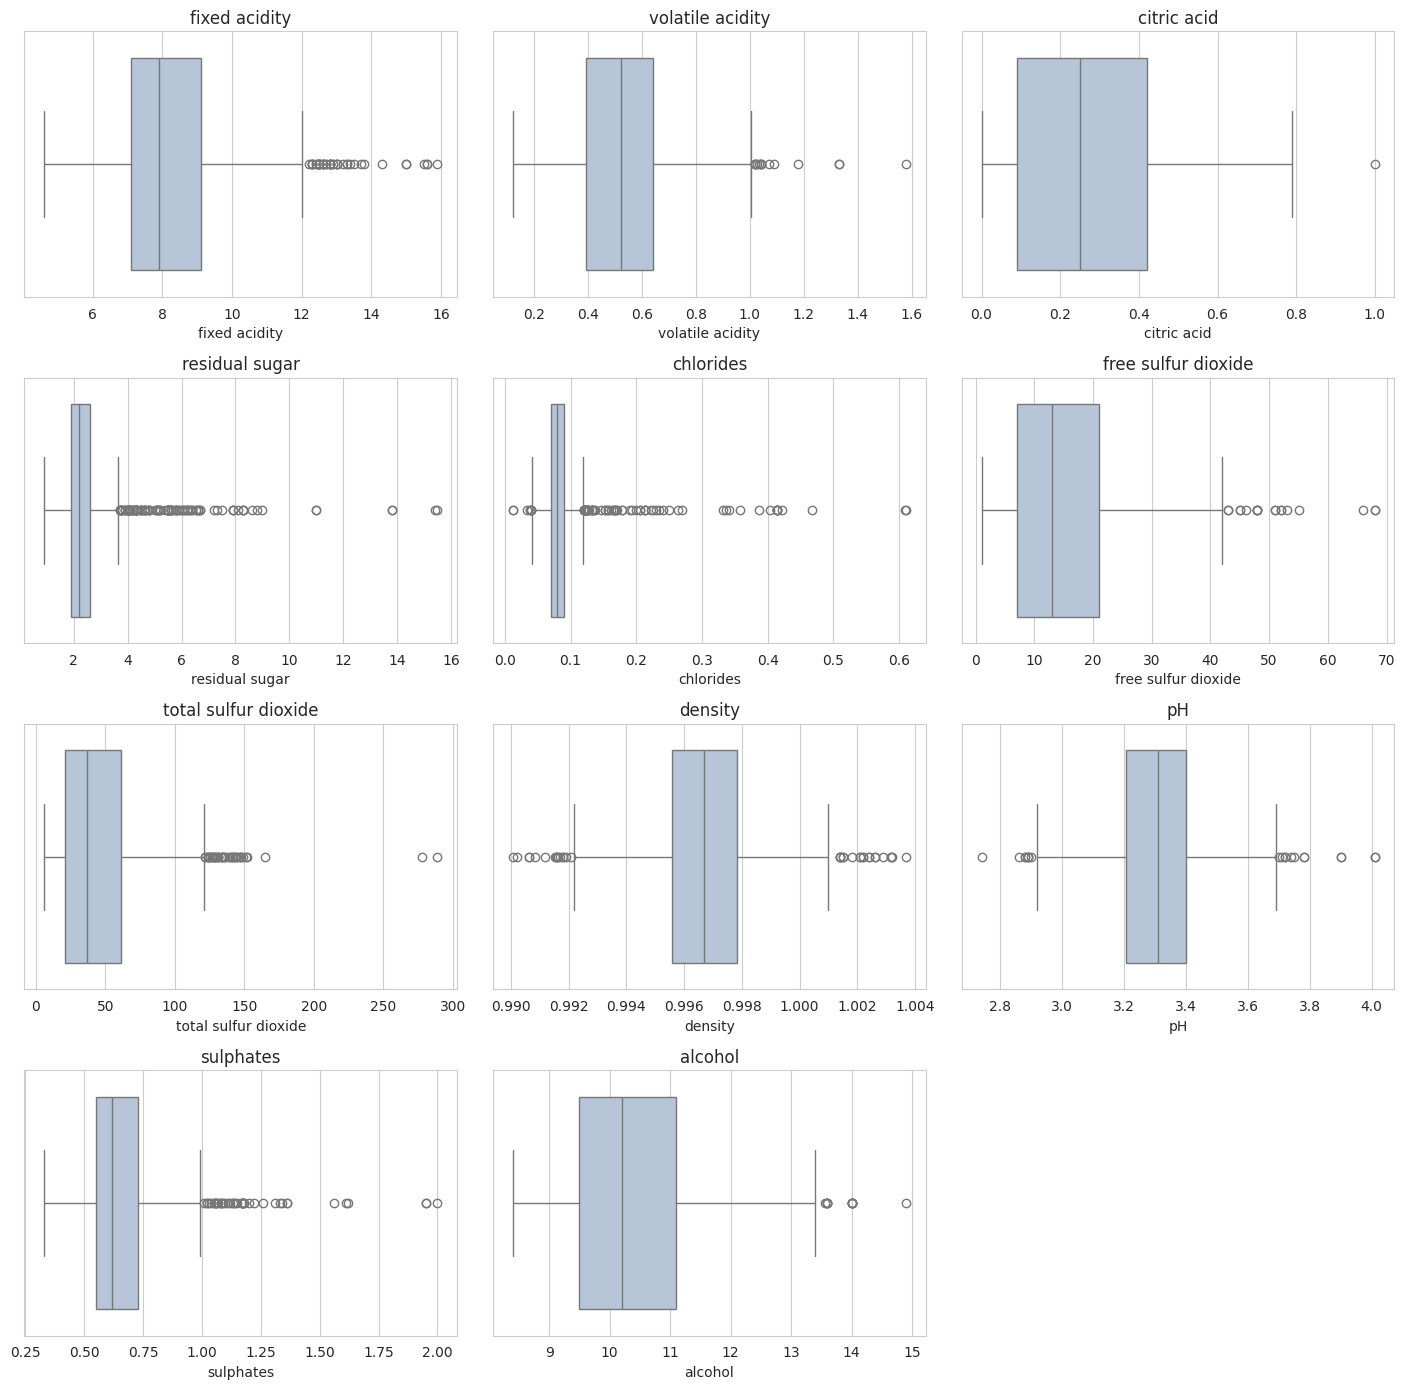

In [8]:
fig, axes = plt.subplots(4, 3, figsize=(14, 14))
axes = axes.flatten()
for i, col in enumerate(features):
    sns.boxplot(x=df[col], ax=axes[i], color="lightsteelblue")
    axes[i].set_title(col)
axes[-1].axis("off")
plt.tight_layout()
plt.show()

In [9]:
outlier_counts = {}
for col in features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_counts[col] = ((df[col] < lower) | (df[col] > upper)).sum()

pd.Series(outlier_counts, name="qtd_outliers").sort_values(ascending=False)

residual sugar          110
chlorides                77
fixed acidity            44
sulphates                43
total sulfur dioxide     40
density                  36
pH                       20
free sulfur dioxide      18
volatile acidity         14
alcohol                  12
citric acid               1
Name: qtd_outliers, dtype: int64

**Interpretação:** existem outliers em praticamente todas as variáveis, mais
concentrados em `residual sugar`, `chlorides`, `sulphates` e `free/total
sulfur dioxide`. Como esses valores extremos são fisicamente plausíveis (não
são erros de digitação) e os modelos usados neste projeto (KNN, Árvore de
Decisão e Random Forest) não pressupõem normalidade dos dados, a decisão —
justificada aqui e aplicada no notebook 02 — é **manter os outliers**, em vez
de removê-los.

### 2.5 Correlação entre variáveis

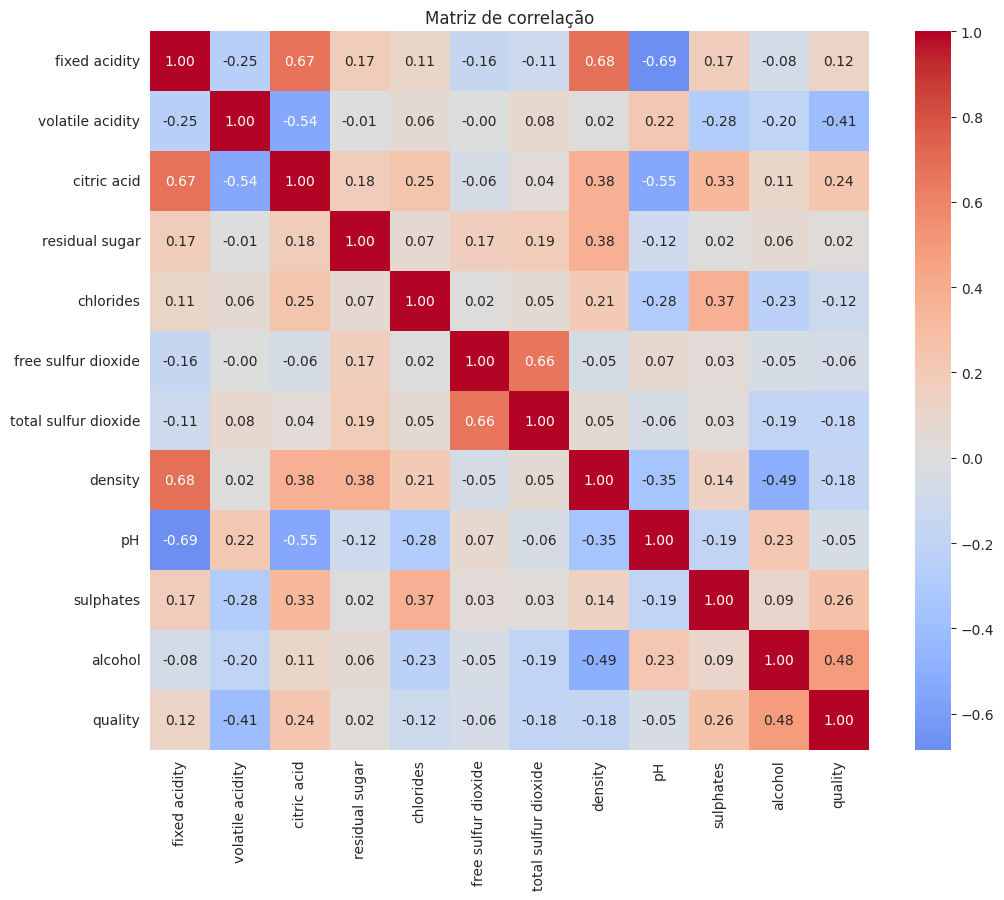

In [10]:
plt.figure(figsize=(11, 9))
corr = df[features + ["quality"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Matriz de correlação")
plt.tight_layout()
plt.show()

In [11]:
corr["quality"].drop(["quality"]).sort_values(key=abs, ascending=False)

alcohol                 0.484866
volatile acidity       -0.407394
sulphates               0.257710
citric acid             0.240821
total sulfur dioxide   -0.183339
density                -0.175208
chlorides              -0.124085
fixed acidity           0.121970
free sulfur dioxide    -0.063260
pH                     -0.052453
residual sugar          0.022002
Name: quality, dtype: float64

**Interpretação das correlações com `quality`:**
- **`alcohol`** é a variável com maior correlação positiva — vinhos com maior
  teor alcoólico tendem a receber notas mais altas.
- **`volatile acidity`** tem a maior correlação negativa — quanto maior a
  acidez volátil (associada a defeitos de fermentação), pior a qualidade
  percebida.
- **`sulphates`** e **`citric acid`** também têm correlação positiva moderada,
  coerente com o papel desses compostos na conservação e no equilíbrio do
  sabor.
- Entre as próprias variáveis explicativas, `fixed acidity` correlaciona-se
  fortemente com `citric acid`, `density` e `pH` — esperado quimicamente, já
  que todas decorrem da composição ácida do vinho. Isso não chega a ser um
  problema para os modelos baseados em árvore usados aqui, mas é bom ter em
  mente ao interpretar importâncias de variáveis isoladamente (retomado no
  notebook 04).

## Resumo para o próximo notebook

- Base sem nulos, com outliers plausíveis (mantidos) e classes desbalanceadas (~14% Alta Qualidade).
- `alcohol`, `volatile acidity`, `sulphates` e `citric acid` são as variáveis mais associadas à qualidade.
- Próximo passo (`02_preprocessamento.ipynb`): remover `Id`, criar features, separar treino/teste de forma estratificada e padronizar as variáveis.